# Enseñar estadística para comprender el mundo

## Del pensamiento estadístico al pensamiento computacional y la inteligencia artificial


**Cuaderno demostrativo para una ponencia de 30 minutos**  
**Contexto:** Caucasia y el Bajo Cauca antioqueño  
**Herramientas:** Python, NumPy, Pandas, Matplotlib y Scikit-learn.


### Propósito
Ejemplificar los cinco momentos de la ponencia mediante pequeñas experiencias reproducibles. 

El hilo conductor será la investigación de un fenómeno territorial: la precipitación.


> **Advertencia sobre los datos:** todos los registros meteorológicos incluidos en este cuaderno son **sintéticos y creados con fines didácticos**. No representan mediciones reales de Caucasia ni deben utilizarse para tomar decisiones sobre riesgos, agricultura o gestión territorial. En una investigación real deben sustituirse por datos verificados, documentando la estación, el periodo, las unidades, los faltantes y la fuente.


## Preparación: importar bibliotecas

Las bibliotecas se incorporan según su función:
- **NumPy:** operaciones numéricas.
- **Pandas:** organización y exploración de datos.
- **Matplotlib:** visualización.
- **Scikit-learn:** construcción y evaluación de un modelo introductorio de aprendizaje automático.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

# Para obtener resultados reproducibles
np.random.seed(42)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.4.6
Pandas: 3.0.3


# Momento 1. El desafío de enseñar estadística hoy
### De calcular una medida a formular preguntas sobre un fenómeno

**Pregunta para abrir la conversación:** ¿qué podemos comprender de las lluvias de Caucasia si únicamente conocemos la precipitación media?

La estadística no comienza necesariamente con una fórmula. Puede comenzar con una pregunta investigable. En este ejemplo exploraremos una semana ficticia de precipitación.


In [3]:
semana = pd.DataFrame({
    "dia": ["Lunes", "Martes", "Miércoles", "Jueves",
            "Viernes", "Sábado", "Domingo"],
    "precipitacion_mm": [0, 2, 0, 5, 0, 28, 7]
})

display(semana)

media = semana["precipitacion_mm"].mean()
print(f"Precipitación media diaria: {media:.1f} mm")

,dia,precipitacion_mm
0,Lunes,0
1,Martes,2
2,Miércoles,0
3,Jueves,5
4,Viernes,0
5,Sábado,28
6,Domingo,7


Precipitación media diaria: 6.0 mm


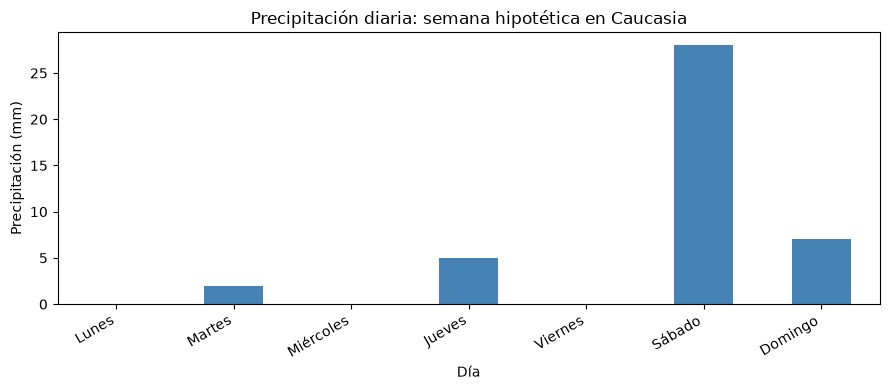

In [4]:
ax = semana.plot(
    x="dia", y="precipitacion_mm", kind="bar",
    legend=False, figsize=(9, 4), color="steelblue"
)
ax.set_title("Precipitación diaria: semana hipotética en Caucasia")
ax.set_xlabel("Día")
ax.set_ylabel("Precipitación (mm)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Discusión didáctica

La media es 6 mm diarios, pero eso **no significa que hayan caído 6 mm cada día**. La media resume el conjunto; no describe por sí sola la distribución temporal.

Preguntas para el auditorio:
1. ¿Qué información ofrece la media?
2. ¿Qué información deja por fuera?
3. ¿Qué otras medidas o representaciones necesitamos?
4. ¿Qué conclusiones sería irresponsable extraer de solo siete observaciones?

**Idea para enfatizar:** saber ejecutar un cálculo no garantiza comprender el fenómeno al que se refiere.

# Momento 2. Aprender estadística investigando
### El ciclo de investigación estadística

Una experiencia escolar puede organizarse en las siguientes etapas:

1. Formular una pregunta.
2. Definir población, unidad de observación y variables.
3. Recolectar o localizar datos.
4. Limpiar y organizar la información.
5. Explorar, representar y analizar.
6. Interpretar y comunicar conclusiones.

En este ejemplo simularemos datos diarios para varios meses. La simulación permite practicar el flujo de análisis, pero no reemplaza la recolección de datos observados.


In [5]:
# Datos sintéticos de precipitación diaria durante un año
fechas = pd.date_range("2025-01-01", periods=365, freq="D")
mes = fechas.month

# Patrón estacional inventado, únicamente para fines didácticos.
# No debe interpretarse como climatología real de Caucasia.
medias_mensuales_sinteticas = {
    1: 4.0, 2: 4.5, 3: 6.0, 4: 8.0, 5: 9.0, 6: 7.0,
    7: 5.0, 8: 5.5, 9: 7.5, 10: 10.0, 11: 9.0, 12: 5.0
}

lluvia = []
for m in mes:
    # Muchos días con cero lluvia y algunos eventos positivos
    prob_lluvia = 0.48
    if np.random.rand() < prob_lluvia:
        valor = np.random.gamma(shape=1.7, scale=medias_mensuales_sinteticas[m] / 1.7)
    else:
        valor = 0.0
    lluvia.append(valor)

clima = pd.DataFrame({
    "fecha": fechas,
    "precipitacion_mm": np.round(lluvia, 1)
})
clima["mes"] = clima["fecha"].dt.month_name()
clima["numero_mes"] = clima["fecha"].dt.month

display(clima.head())
print("Número de registros:", len(clima))
print("Fechas:", clima["fecha"].min().date(), "a", clima["fecha"].max().date())

,fecha,precipitacion_mm,mes,numero_mes
0,2025-01-01,1.0,January,1
1,2025-01-02,4.2,January,1
2,2025-01-03,0.0,January,1
3,2025-01-04,0.0,January,1
4,2025-01-05,1.9,January,1


Número de registros: 365
Fechas: 2025-01-01 a 2025-12-31


### Definir la pregunta y las variables

**Pregunta de investigación didáctica:** ¿cómo varía la precipitación diaria entre los meses del año simulado?

- Unidad de observación: un día.
- Variable principal: precipitación diaria, medida en milímetros.
- Variable temporal: fecha y mes.
- Tipo de variable principal: cuantitativa continua, registrada aquí con un decimal.

En una investigación real habría que identificar la estación meteorológica, su ubicación, el instrumento, el periodo de observación y los procedimientos de control de calidad.

In [6]:
# Revisar estructura, tipos de datos y posibles valores faltantes
clima.info()

print("\\nValores faltantes:")
display(clima.isna().sum().to_frame("cantidad"))

print("\\nResumen descriptivo:")
display(clima["precipitacion_mm"].describe().to_frame())

<class 'pandas.DataFrame'>
RangeIndex: 365 entries, 0 to 364
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   fecha             365 non-null    datetime64[us]
 1   precipitacion_mm  365 non-null    float64       
 2   mes               365 non-null    str           
 3   numero_mes        365 non-null    int32         
dtypes: datetime64[us](1), float64(1), int32(1), str(1)
memory usage: 12.3 KB
\nValores faltantes:


,cantidad
fecha,0
precipitacion_mm,0
mes,0
numero_mes,0


\nResumen descriptivo:


,precipitacion_mm
count,365.000000
mean,2.966027
std,4.434622
min,0.000000
25%,0.000000
50%,0.000000
75%,4.700000
max,26.100000


In [7]:
# Resumir la precipitación por mes
resumen_mensual = (
    clima.groupby("numero_mes")["precipitacion_mm"]
    .agg(["count", "mean", "median", "sum", "std", "max"])
    .round(2)
)

nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun",
                 "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
resumen_mensual.index = nombres_meses
display(resumen_mensual)

,count,mean,median,sum,std,max
Ene,31,2.66,1.9,82.5,2.56,8.6
Feb,28,0.95,0.0,26.6,1.43,3.9
Mar,31,2.56,0.0,79.3,3.50,11.2
Abr,30,2.24,0.0,67.1,3.98,12.6
May,31,1.29,0.0,39.9,2.48,8.7
Jun,30,4.16,0.6,124.9,5.82,20.3
Jul,31,3.13,2.1,97.0,3.97,13.7
Ago,31,3.60,0.0,111.5,5.03,16.0
Sep,30,3.05,0.0,91.4,4.92,16.2
Oct,31,5.62,2.8,174.1,7.13,26.1


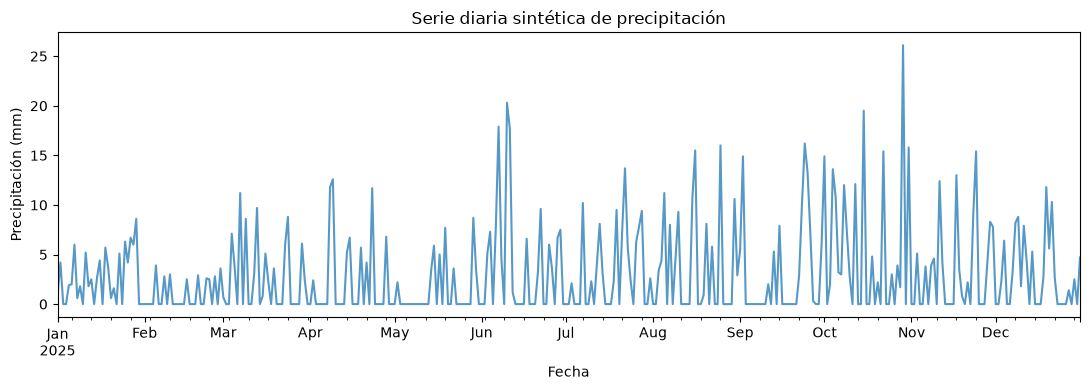

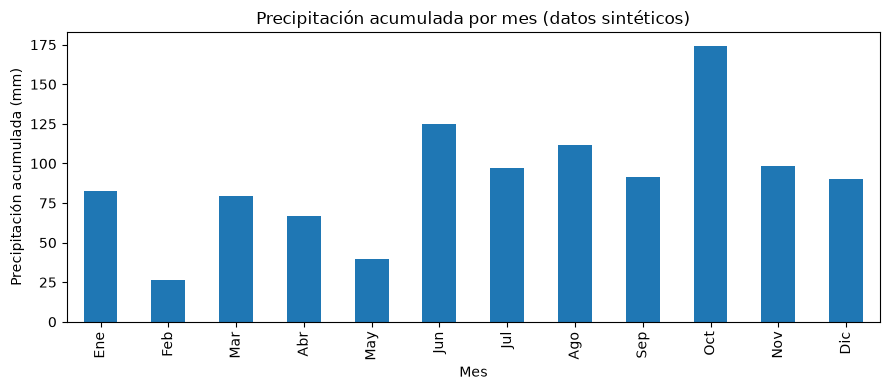

In [8]:
ax = clima.plot(
    x="fecha", y="precipitacion_mm",
    figsize=(11, 4), legend=False, alpha=0.75
)
ax.set_title("Serie diaria sintética de precipitación")
ax.set_xlabel("Fecha")
ax.set_ylabel("Precipitación (mm)")
plt.tight_layout()
plt.show()

ax = resumen_mensual["sum"].plot(kind="bar", figsize=(9, 4))
ax.set_title("Precipitación acumulada por mes (datos sintéticos)")
ax.set_xlabel("Mes")
ax.set_ylabel("Precipitación acumulada (mm)")
plt.tight_layout()
plt.show()

### Interpretar antes de concluir

Las gráficas y tablas permiten formular nuevas preguntas, pero no autorizan a afirmar que esos patrones ocurren realmente en Caucasia. En el aula, los estudiantes pueden distinguir entre:
- lo que muestran los datos;
- lo que inferimos razonablemente;
- lo que todavía no sabemos;
- los datos adicionales que necesitamos.

**Actividad:** pedir al grupo que redacte una conclusión de dos frases y una pregunta nueva que surja del análisis.

# Momento 3. Python y pensamiento computacional
### Comparar, describir y visualizar antes de explicar

Ahora comparamos dos semanas con la misma precipitación total y la misma media, pero con distribuciones muy distintas. Esta comparación muestra por qué una sola medida no es suficiente.


In [9]:
semana_A = np.array([0, 2, 0, 5, 0, 28, 7])
semana_B = np.array([6, 6, 6, 6, 6, 6, 6])

comparacion = pd.DataFrame({
    "Semana A": semana_A,
    "Semana B": semana_B
})

indicadores = comparacion.agg(["sum", "mean", "median", "std", "max"]).round(2)
display(indicadores)

,Semana A,Semana B
sum,42.00,42.0
mean,6.00,6.0
median,2.00,6.0
std,10.08,0.0
max,28.00,6.0


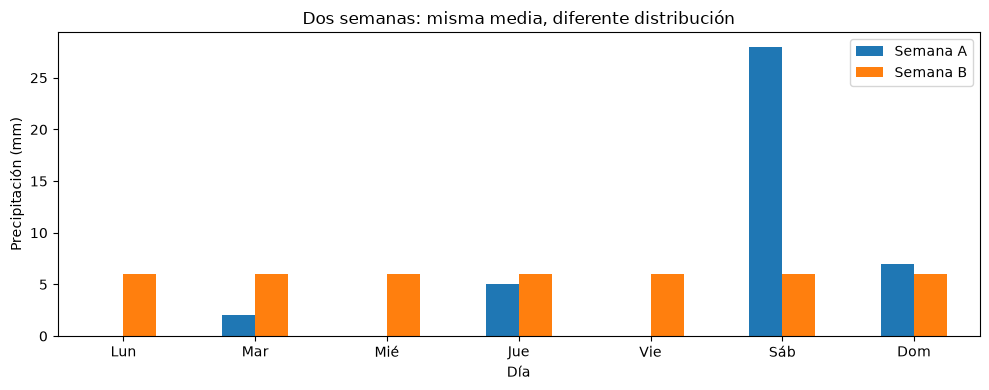

In [10]:
ax = comparacion.plot(kind="bar", figsize=(10, 4))
ax.set_title("Dos semanas: misma media, diferente distribución")
ax.set_xlabel("Día")
ax.set_ylabel("Precipitación (mm)")
ax.set_xticklabels(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], rotation=0)
plt.tight_layout()
plt.show()

### ¿Dónde aparece el pensamiento computacional?

- **Descomposición:** separar el problema en recolección, limpieza, resumen y visualización.
- **Reconocimiento de patrones:** observar concentración, regularidad y valores extremos.
- **Abstracción:** decidir qué variables son pertinentes para responder la pregunta.
- **Algoritmos:** especificar los pasos para calcular indicadores.
- **Automatización:** repetir el análisis para diferentes semanas o meses.
- **Evaluación:** comprobar que el código y las conclusiones sean coherentes.

La programación no reemplaza la comprensión conceptual. Hace explícitos los procedimientos y permite repetirlos, inspeccionarlos y modificarlos.

In [11]:
# Construir una función reutilizable para resumir datos
def resumir_precipitacion(valores):
    valores = np.asarray(valores, dtype=float)
    return pd.Series({
        "n_observaciones": len(valores),
        "total_mm": np.sum(valores),
        "media_mm": np.mean(valores),
        "mediana_mm": np.median(valores),
        "desviacion_estandar_mm": np.std(valores, ddof=1),
        "dias_sin_lluvia": np.sum(valores == 0),
        "maximo_diario_mm": np.max(valores)
    })

display(pd.DataFrame({
    "Semana A": resumir_precipitacion(semana_A),
    "Semana B": resumir_precipitacion(semana_B)
}).round(2))

,Semana A,Semana B
n_observaciones,7.00,7.0
total_mm,42.00,42.0
media_mm,6.00,6.0
mediana_mm,2.00,6.0
desviacion_estandar_mm,10.08,0.0
dias_sin_lluvia,3.00,0.0
maximo_diario_mm,28.00,6.0


### Preguntas de reflexión

1. ¿Por qué las dos semanas tienen la misma media?
2. ¿Por qué la desviación estándar ayuda a distinguirlas?
3. ¿Qué medida sería más informativa para una pregunta sobre regularidad?
4. ¿Qué información adicional se requeriría para estudiar posibles impactos en movilidad o inundaciones?

No se debe inferir riesgo de inundación únicamente a partir de una media semanal. Se necesitarían, entre otros elementos, intensidad y duración de los eventos, condiciones del suelo, drenaje, topografía y registros locales.

# Momento 4. De la estadística descriptiva al Machine Learning
### Un primer modelo predictivo, con límites explícitos

Para introducir Machine Learning se utilizará un conjunto sintético de observaciones. 

El objetivo será predecir una variable numérica a partir de dos características: temperatura y humedad.

**Importante:** 
* este ejemplo ilustra el flujo técnico de un modelo de regresión.
* No es un modelo meteorológico validado ni permite pronosticar el clima de Caucasia.

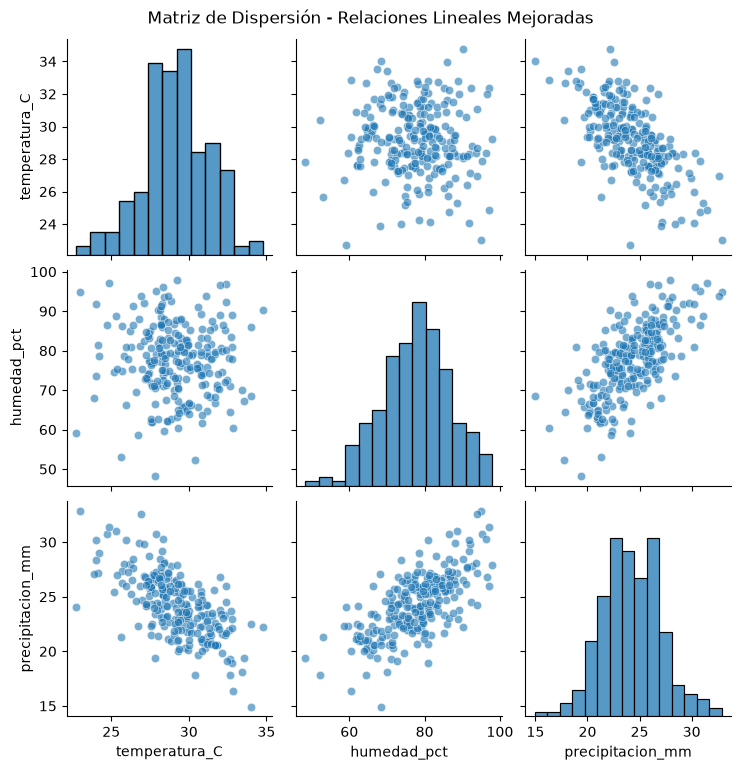

Matriz de Correlación:
                  temperatura_C  humedad_pct  precipitacion_mm
temperatura_C              1.00        -0.04             -0.66
humedad_pct               -0.04         1.00              0.68
precipitacion_mm          -0.66         0.68              1.00


In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Generar datos sintéticos
rng = np.random.default_rng(123)
n = 240

temperatura = rng.normal(loc=29, scale=2.2, size=n)
humedad = np.clip(rng.normal(78, 9, n), 45, 98)

# 2. Relación artificial MEJORADA
# Le damos más peso negativo a la temperatura (-0.9) y reducimos el ruido (1.0)
# para que la relación lineal sea visualmente clara en los scatter plots.
ruido = rng.normal(0, 1.0, n) 
precipitacion_simulada = (
    0.20 * humedad          # Menor peso para que no opaque a la temperatura
    - 0.90 * temperatura    # Mayor peso negativo para notar la pendiente claramente
    + 35.0                  # Offset ajustado para que la media siga siendo positiva
    + ruido
)

datos_modelo = pd.DataFrame({
    "temperatura_C": temperatura,
    "humedad_pct": humedad,
    "precipitacion_mm": precipitacion_simulada
})

# 3. Mostrar la matriz de dispersión mejorada
# Usamos seaborn para que se vea más estético (opcional, pero recomendado)
sns.pairplot(datos_modelo, kind='scatter', plot_kws={'alpha': 0.6})
plt.suptitle("Matriz de Dispersión - Relaciones Lineales Mejoradas", y=1.02)
plt.show()

# Imprimir matriz de correlación para confirmar los valores
print("Matriz de Correlación:")
print(datos_modelo.corr().round(2))

In [29]:
display(datos_modelo.describe().round(2))

,temperatura_C,humedad_pct,precipitacion_mm
count,240.00,240.00,240.00
mean,29.16,77.61,24.25
std,2.14,9.13,2.90
min,22.73,48.32,14.93
25%,27.85,71.81,22.28
50%,29.16,78.17,24.16
75%,30.77,83.35,26.14
max,34.78,98.00,32.89


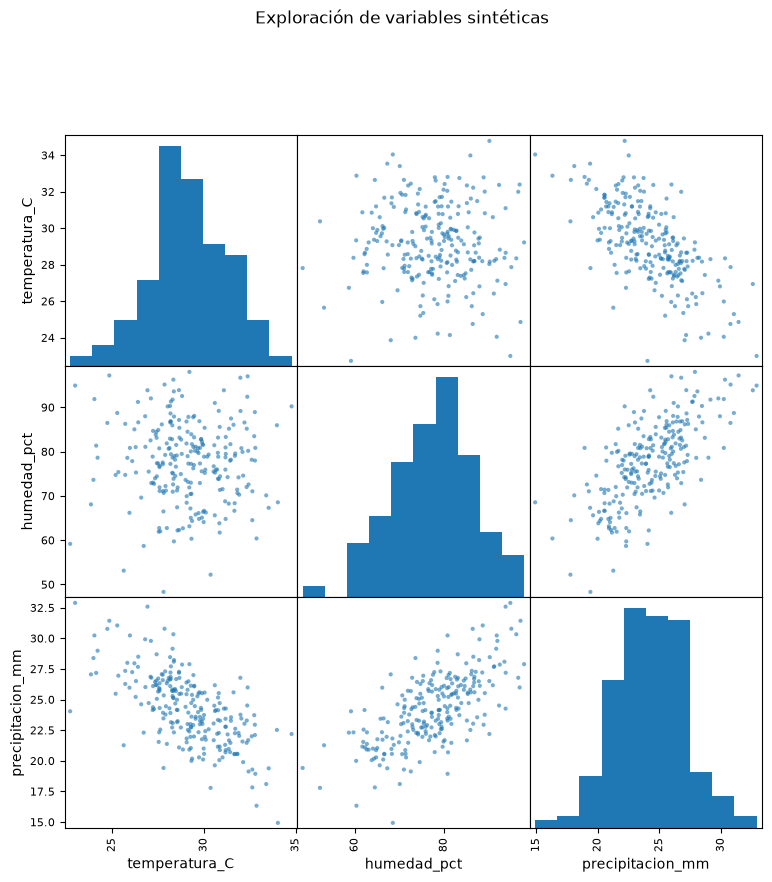

In [31]:
# Explorar relaciones entre las variables
pd.plotting.scatter_matrix(
    datos_modelo,
    figsize=(9, 9),
    diagonal="hist",
    alpha=0.6
)
plt.suptitle("Exploración de variables sintéticas", y=1.02)
plt.savefig('matriz_scatter.png')
plt.show()

In [32]:
display(datos_modelo.corr().round(2))

,temperatura_C,humedad_pct,precipitacion_mm
temperatura_C,1.00,-0.04,-0.66
humedad_pct,-0.04,1.00,0.68
precipitacion_mm,-0.66,0.68,1.00


### Separar datos de entrenamiento y prueba

El conjunto de entrenamiento se utiliza para ajustar el modelo. El conjunto de prueba se reserva para evaluar su desempeño con observaciones que el modelo no utilizó durante el ajuste.

Esta separación ayuda a detectar si el modelo simplemente se ajusta a los datos conocidos. No garantiza por sí sola que el modelo generalice a otras estaciones, temporadas o regiones.

In [33]:
X = datos_modelo[["temperatura_C", "humedad_pct"]]
y = datos_modelo["precipitacion_mm"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

In [34]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[-0.85, 0.21]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['temperatura_C','humedad_pct']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,32.49
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [35]:
predicciones = modelo.predict(X_test)

In [36]:
mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

In [37]:
print("Intercepto:", round(modelo.intercept_, 3))
print("Coeficientes:", dict(zip(X.columns, modelo.coef_.round(3))))
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.2f}")

Intercepto: 32.488
Coeficientes: {'temperatura_C': np.float64(-0.848), 'humedad_pct': np.float64(0.214)}
MAE:  0.95
RMSE: 1.15
R²:   0.84


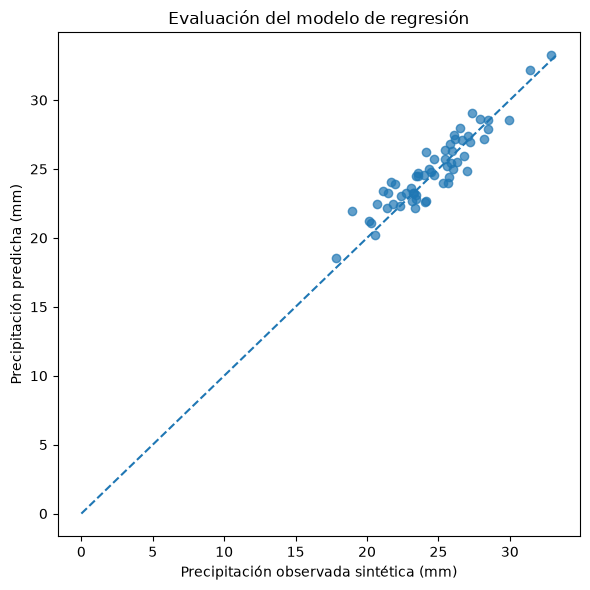

In [38]:
# Comparar valores observados y predichos
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predicciones, alpha=0.7)
limite = max(y_test.max(), predicciones.max())
plt.plot([0, limite], [0, limite], linestyle="--")
plt.xlabel("Precipitación observada sintética (mm)")
plt.ylabel("Precipitación predicha (mm)")
plt.title("Evaluación del modelo de regresión")
plt.tight_layout()
plt.show()

### Interpretar el modelo críticamente

- **MAE:** error absoluto medio, expresado en las mismas unidades de la variable objetivo.
- **RMSE:** penaliza más los errores grandes.
- **R²:** resume qué proporción de la variabilidad de la variable objetivo explica el modelo en el conjunto evaluado, según la definición del coeficiente de determinación.

Un modelo puede producir predicciones y aun así ser inadecuado para tomar decisiones. Debemos preguntar:
- ¿Los datos representan el fenómeno real?
- ¿Hay suficientes observaciones?
- ¿Existen variables importantes que no se incluyeron?
- ¿El modelo funciona en otros periodos?
- ¿Qué consecuencias tendría equivocarse?

**Conexión con Deep Learning:** 
* las redes neuronales también aprenden patrones a partir de datos y requieren evaluación, validación y análisis crítico.
* No es necesario entrenar una red neuronal compleja en primaria para introducir estas ideas: se puede comenzar comprendiendo qué son:
  * los datos,
  * las variables,
  * los patrones,
  * las predicciones
  * y los errores.

# Momento 5. Una propuesta para transformar la enseñanza
### Diseñar experiencias según la progresión escolar

La tecnología debe ajustarse a los objetivos de aprendizaje y al desarrollo de los estudiantes.   

La siguiente tabla sintetiza una posible progresión.


In [39]:
progresion = pd.DataFrame([
    {
        "Nivel": "Primaria",
        "Pregunta tipo": "¿Cuál es la fruta preferida del grupo?",
        "Ideas estadísticas": "Recolección, conteo, frecuencia y gráficos",
        "Pensamiento computacional": "Clasificar, ordenar y reconocer patrones",
        "Tecnología posible": "Material concreto, hojas de cálculo y gráficos sencillos"
    },
    {
        "Nivel": "Secundaria básica",
        "Pregunta tipo": "¿Cómo varía la lluvia entre semanas?",
        "Ideas estadísticas": "Media, mediana, dispersión y probabilidad",
        "Pensamiento computacional": "Descomposición, algoritmos y automatización",
        "Tecnología posible": "Python, Jupyter, Pandas y Matplotlib"
    },
    {
        "Nivel": "Educación media",
        "Pregunta tipo": "¿Podemos modelar una variable a partir de otras?",
        "Ideas estadísticas": "Muestreo, correlación, regresión y error",
        "Pensamiento computacional": "Modelado, prueba y evaluación",
        "Tecnología posible": "Python y Scikit-learn; introducción conceptual a redes neuronales"
    }
])

display(progresion)

,Nivel,Pregunta tipo,Ideas estadísticas,Pensamiento computacional,Tecnología posible
0,Primaria,¿Cuál es la fruta preferida del grupo?,"Recolección, conteo, frecuencia y gráficos","Clasificar, ordenar y reconocer patrones","Material concreto, hojas de cálculo y gráficos..."
1,Secundaria básica,¿Cómo varía la lluvia entre semanas?,"Media, mediana, dispersión y probabilidad","Descomposición, algoritmos y automatización","Python, Jupyter, Pandas y Matplotlib"
2,Educación media,¿Podemos modelar una variable a partir de otras?,"Muestreo, correlación, regresión y error","Modelado, prueba y evaluación",Python y Scikit-learn; introducción conceptual...


## Actividad de cierre: diseñar una pregunta investigable

Cada estudiante o equipo propone una pregunta sobre su escuela o territorio y completa:

1. **Fenómeno:** ¿qué situación desea comprender?
2. **Pregunta investigable:** ¿qué quiere averiguar exactamente?
3. **Unidad de observación:** ¿qué o quién se observará?
4. **Variables:** ¿qué datos necesita y en qué unidades?
5. **Fuente y ética:** ¿cómo obtendrá los datos? ¿requiere consentimiento? ¿cómo protegerá la privacidad?
6. **Análisis:** ¿qué tablas, gráficos o medidas utilizará?
7. **Conclusión:** ¿qué tipo de afirmaciones permitirán los datos y cuáles no?

Ejemplos de preguntas:
- ¿Cómo varía la temperatura registrada en diferentes momentos del día?
- ¿Qué medios de transporte utilizan los estudiantes para llegar a la institución?
- ¿Cómo se distribuyen los tiempos de desplazamiento al colegio?
- ¿Qué relación se observa entre dos variables ambientales disponibles en una fuente confiable?

Evitar recolectar datos personales identificables cuando no sean necesarios. Para actividades escolares, priorizar datos agregados, anónimos y con autorización cuando corresponda.

# Síntesis para cerrar la ponencia

La secuencia completa puede resumirse así:

**Pregunta → Datos → Exploración → Interpretación → Modelo → Decisión fundamentada**

Tres mensajes para la audiencia:

1. Enseñar estadística es enseñar a pensar con datos, no solamente a calcular.
2. El pensamiento computacional y Python amplían las posibilidades de explorar, representar y analizar información.
3. La alfabetización estadística ayuda a comprender y cuestionar los modelos de inteligencia artificial, sus errores, sesgos e incertidumbres.

> **Pregunta final:** ¿estamos enseñando a nuestros estudiantes a calcular con datos o a pensar con datos?

---

## Referencias y recursos para profundizar

- [NumPy: documentación oficial](https://numpy.org/doc/)
- [Pandas: documentación oficial](https://pandas.pydata.org/docs/)
- [Matplotlib: documentación oficial](https://matplotlib.org/stable/)
- [Scikit-learn: documentación oficial](https://scikit-learn.org/stable/)
- [IDEAM: portal institucional](https://www.ideam.gov.co/)

**Sugerencia para convertir la demostración en una investigación real:** 
* descargar registros meteorológicos verificables, documentar su procedencia y metadatos, revisar faltantes y valores atípicos, y comparar los resultados con los obtenidos en este cuaderno sintético.
* No mezclar datos simulados y observados sin identificarlos claramente.